# Assignment 4: Image Classification

In this assignment, you will classify images using the [**Darknet framework**](https://darknetcv.ai/api/). You will use OpenCV library and the [**DNN module**](https://docs.opencv.org/4.x/d2/d58/tutorial_table_of_content_dnn.html), which are very fast due to the optimizations inherent in the OpenCV library.

**Step 1: Learning- Classifying one image**

1. Familiarze yourself with popular pre-trained models
2. Learn how to load and apply an image classification model
3. Experiment with the model using additional image examples

**Step 2: Assignment- Classifying Several Images**


## Step 1: Learning - Background

### **Popular pre-trained models**

The OpenCV supports many [**state-of-the-art models**](https://github.com/opencv/opencv/wiki/Deep-Learning-in-OpenCV) including YOLO, TensorFlow, PyTorch, and Caffee. [**This github repo**](https://github.com/opencv/opencv/tree/master/samples/dnn) contains several sample code for several models.

### **Frameworks**

Some popular deep learning frameworks:

*  **Caffe**

You can use the following function to read a network model stored in Caffe framework's format **`readNetFromCaffe()`**. More info here [**`cv2.dnn.readNetFromCaffe()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga29d0ea5e52b1d1a6c2681e3f7d68473a)

*  **TensorFlow**

You can use the following function to read a network model stored in [TensorFlow](https://www.tensorflow.org/) framework's format:
**`readNetFromTensorflow()`**. More info here [**`cv2.dnn.readNetFromTensorflow()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#gad820b280978d06773234ba6841e77e8d)

*  **Torch and PyTorch**

For loading Torch model files, we need the file containing the pre-trained weights. Generally, this file has a `.t7` or `.net` extension.

You can use the following function to read a network model stored in [Torch7](http://torch.ch/) framework's format **`readNetFromTorch()`**. More info here [**`cv2.dnn.readNetFromTorch()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga65a1da76cb7d6852bdf7abbd96f19084)

*  **Darknet**

You can use the following function to read a network model stored in [Darknet](https://pjreddie.com/darknet/) model files: **`readNetFromDarknet()`**. More info here [**`cv2.dnn.readNetFromDarknet()`**](https://docs.opencv.org/3.4/d6/d0f/group__dnn.html#gafde362956af949cce087f3f25c6aff0d)

*  **Reading any DNN model**

You can use the following function to read deep learning network in any supported format and returns a `Net` object **`readNet()`**. More info here [**`cv2.dnn.readNet()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga3b34fe7a29494a6a4295c169a7d32422)

## Image Classification using DNN

For this assignment, you will implement one of the most common computer vision problems using the DNN module. You will use the [**DenseNet121**](https://huggingface.co/qualcomm/DenseNet-121) deep neural network model for classifying images into 1000 classes of [*ImageNet*](https://www.google.com/url?sa=t&rct=j&q=&esrc=s&source=web&cd=&cad=rja&uact=8&ved=2ahUKEwjasLG-yKbyAhW3IbcAHRW1BZkQFnoECAwQAw&url=https%3A%2F%2Fwww.image-net.org%2F&usg=AOvVaw07SoUbpxRQk8ZNEiJoLqt5) dataset.

* The model DenseNet-121 full python code can be found [*here*](https://github.com/pytorch/vision/blob/main/torchvision/models/densenet.py)

* Pretrained DenseNet Models on ImageNet [*DenseNet-Caffee*](https://github.com/shicai/DenseNet-Caffe)


To classify an image, you will go through the following process:

1. Read the class labels from a .txt file – This file contains the names of all the objects the model can recognize.
2. Load the pre-trained neural network using `readNet` function to import the model from disk.
3. Import the input image you want to classify.
4. Convert the image into a blob using `blobFromImage` function.
5. Use the function `setInput` to feed the blob into the network.
6. Run the model to get predictions (`forward`)


In [118]:
#Import the libraries
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Read the ImageNet class names from the input folder (classification_classes_ILSVRC2012.txt')
with open('input/classification_classes_ILSVRC2012.txt', 'r') as f:
    image_net_names = f.read().split('\n')

# Save all available classification labels, excluding the empty line at the end.
class_names = image_net_names[:-1]

# Verify the size, and inspect one of the classes by name.
print(len(class_names), class_names[100])

1000 black swan, Cygnus atratus


In [119]:
# 2. Loading the Classification model (caffe) using readNet function.
config_file = 'models/DenseNet_121.prototxt'
model_file = 'models/DenseNet_121.caffemodel'

model = cv2.dnn.readNet(model=model_file, config=config_file, framework='Caffe')

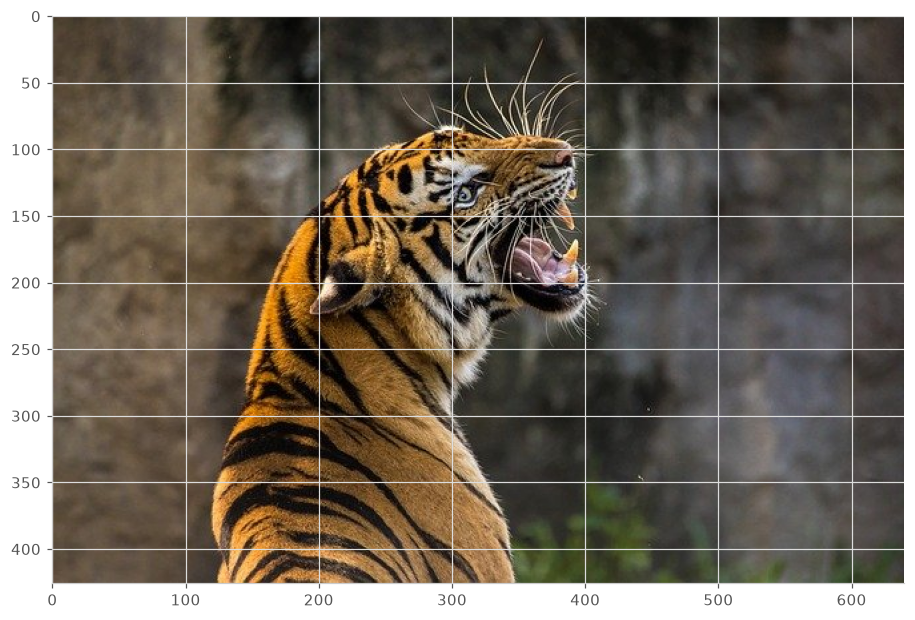

In [120]:
# 3. Import the image you want to classify.
tiger_img = cv2.imread('input/image1.jpg')
plt.figure(figsize=[10, 10])
plt.imshow(tiger_img[:, :, ::-1]);

4. Convert the image into a blob.

The blob speficications are given at the top of in `DenseNet_121.prototxt`:
```
name: "DENSENET_121"
input: "data"
input_dim: 1  -- Number of images per blob
input_dim: 3   --- Number of channels per image (full color, no alpha)
input_dim: 224   ---(height)
input_dim: 224    ---(width)
```

The mean and scalefactor to use also come from the model itself ([see here](https://github.com/shicai/DenseNet-Caffe)).

In [121]:
# 4. Convert the image into a blob. The blob specifications are found in DenseNet_121.prototxt.
blob = cv2.dnn.blobFromImage(
    image=tiger_img, scalefactor=0.017, size=(224, 224), mean=(104, 117, 123), swapRB=False, crop=False)

In [122]:
# 5. Set the input blob for the neural network.
model.setInput(blob)

In [123]:
# 6. Forward the blob through the network.
outputs = model.forward()
final_outputs = outputs[0]

In [124]:
# Make all the outputs 1D, where each represents likihood of matching one of the 1K classification groups.
final_outputs = final_outputs.reshape(1000, 1)

# Get the class label index with the max confidence.
label_id = np.argmax(final_outputs)

# Convert score to probabilities for all matches.
probs = np.exp(final_outputs) / np.sum(np.exp(final_outputs))

print(probs[:10])
print("Max probability:", np.max(probs))

[[2.1499585e-10]
 [4.0102185e-10]
 [4.2768603e-10]
 [3.2427311e-10]
 [1.6526440e-11]
 [1.6457802e-11]
 [1.5199699e-11]
 [4.4728012e-09]
 [5.0410884e-09]
 [1.1915433e-09]]
Max probability: 0.9372195


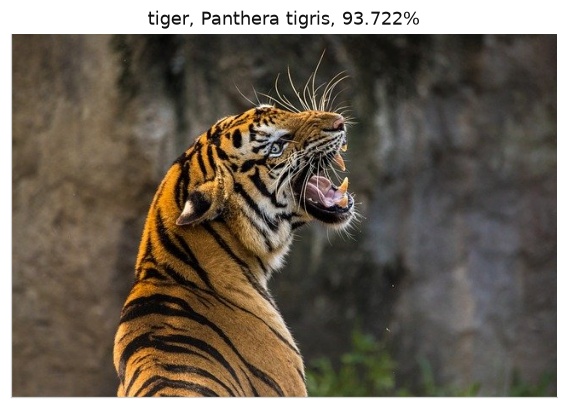

In [125]:
# Get the final highest probability
final_prob = np.max(probs) * 100.0

# Map the max confidence to the class label names.
out_name = class_names[label_id]
out_text = f"{out_name}, {final_prob:.3f}%"

# Display the image, best matched classification, and confidence.
plt.imshow(tiger_img[:, :, ::-1])
plt.title(out_text)
plt.xticks([]), plt.yticks([])
plt.show() 

# Step 2- Assignment: classifying several images

Now that you have successfully implemented Image classification workflow, it's time to apply the model to multiple examples and create a reusable function for batch processing.

We can now give a try at applying the model to more examples. To more neatly use our workflow, we have defined the prios steps into the below reusable function.
Now let us use this function to classify a whole folder of images. Feel free to drop in some of your own jpg images into the `input` folder if you want to see what the model comes up with.


In [126]:
# Formatting. Claud HEVELY USED HERE.
# Extra imports and a plotting style for this part
import os
import time
import shutil
import pandas as pd

print("OpenCV version:", cv2.__version__)

# Colours. One blue for a single line of numbers and three steps of the same blue for the
# first, second and third guess, so that rank is readable without a legend.
ACCENT = "#2a78d6"
RANK_COLOURS = ["#1c5cab", "#3987e5", "#86b6ef"]
INK = "#111111"
INK_SOFT = "#555555"
WARN = "#e34948"

plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#cccccc",
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linewidth": 0.8,
    "text.color": INK,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "font.size": 10,
    "figure.dpi": 110,
})


def short(label):
    """ImageNet gives every class a list of synonyms. The first one is the everyday name."""
    return label.split(",")[0].strip()


def class_index(name):
    """Find the position of a class from its everyday name, used to follow one class in a test."""
    for i, full in enumerate(class_names):
        if short(full) == name:
            return i
    raise ValueError(f"no class called {name}")


print("Ready")

OpenCV version: 4.14.0
Ready


In [127]:
# 1. Create a function containing all 6 steps to classify an image
#YOUR CODE HERE

def classify_image(image, top_k=3, net=None, names=None):
    net = model if net is None else net
    names = class_names if names is None else names

    if isinstance(image, str):
        name = os.path.basename(image)
        img = cv2.imread(image)
        if img is None:
            print("ERROR")
    else:
        name = ""
        img = image
    blob = cv2.dnn.blobFromImage(
        image = img, scalefactor=0.017, size=(224, 224), mean=(104, 117, 123), swapRB=False, crop=False
    )

    net.setInput(blob)
    scores = net.forward()[0].reshape(1000)

    scoreExp = np.exp(scores - scores.max())
    prob = 100.0 * scoreExp / scoreExp.sum()

    best = np.argsort(prob)[::-1][:top_k]
    return {
        "name": name,
        "image": img,
        "labels": [names[i] for i in best],
        "prob": [float(prob[i]) for i in best],
        "all_probs": prob,
    }

def class_folder(folder, patterns = ("*.jpg", "*.jpeg", "*.png"), top_k = 3):
    paths = sorted(p for pattern in patterns for p in glob.glob(os.path.join(folder, pattern)))
    return [classify_image(p, top_k = top_k) for p in paths]

def results_table(results):
    rows = []
    for r in results:
        rows.append({
            "image": r["name"],
            "best match": short(r["labels"][0]),
            "confidence": round(r["prob"][0], 2),
            "second guess": short(r["labels"][1]),
            "second": round(r["prob"][1], 2),
            "third guess": short(r["labels"][2]),
            "third": round(r["prob"][2], 2)
        })
    return pd.DataFrame(rows).set_index("image")

def show_images(results, coloms = 3, suptitle = None): # claud HEVELY used here
    rows = int(np.ceil(len(results) / coloms))
    fig, axes = plt.subplots(rows, coloms, figsize = (4.3 * coloms, 4.6 * rows), squeeze = False)
    for ax, r in zip(axes.ravel(), results):
        ax.imshow(r["image"][:, :, ::-1])
        ax.set_title(f"{short(r['labels'][0])}\n{r['prob'][0]:.1f} percent", fontsize = 10)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    for ax in axes.ravel()[len(results):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize = 13, y = 1.0)
    plt.tight_layout()
    plt.show()

def show_confidence(results, coloms = 3, suptitle = None): # Claude HEVELY used here
    rows = int(np.ceil(len(results) / coloms))
    fig, axes = plt.subplots(rows, coloms, figsize = (4.6 * coloms, 2.5 * rows), squeeze = False)
    for ax, r in zip(axes.ravel(), results):
        y = np.arange(len(r["labels"]))
        ax.barh(y, r["prob"], height = 0.62, color = RANK_COLOURS[:len(y)])
        ax.set_yticks(y)
        ax.set_yticklabels([short(lbl) for lbl in r["labels"]], fontsize = 8)
        ax.invert_yaxis()
        ax.set_xlim(0, 122)
        ax.set_axisbelow(True)
        ax.set_title(r["name"], fontsize = 10)
        ax.set_xlabel("confidence in percent", fontsize = 8)
        ax.grid(axis="y", visible = False)
        for yy, p in zip(y, r["prob"]):
            ax.text(p + 3, yy, f"{p:.1f}", va ="center", fontsize = 8, color = INK_SOFT)
    for ax in axes.ravel()[len(results):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize = 14, y= 1.0)
    plt.tight_layout()
    plt.show()

print("\ndef done\n")


# 2. Test Your Implementation
# Use the function you created to classify all the images from the folder "input".
# YOUR CODE HERE

results = class_folder("./input")
print(f"{len(results)} images classified\n")
results_table(results)



def done

6 images classified



,best match,confidence,second guess,second,third guess,third
image,,,,,,
image1.jpg,tiger,93.72,tiger cat,6.15,jaguar,0.11
image2.jpg,balloon,99.74,parachute,0.21,maraca,0.02
image3.jpg,acoustic guitar,99.41,electric guitar,0.33,banjo,0.22
image4.jpg,Eskimo dog,83.39,Siberian husky,14.44,dogsled,1.30
image5.jpg,jellyfish,91.99,hermit crab,4.33,electric ray,0.42
image6.jpg,school bus,99.58,jeep,0.11,minibus,0.08


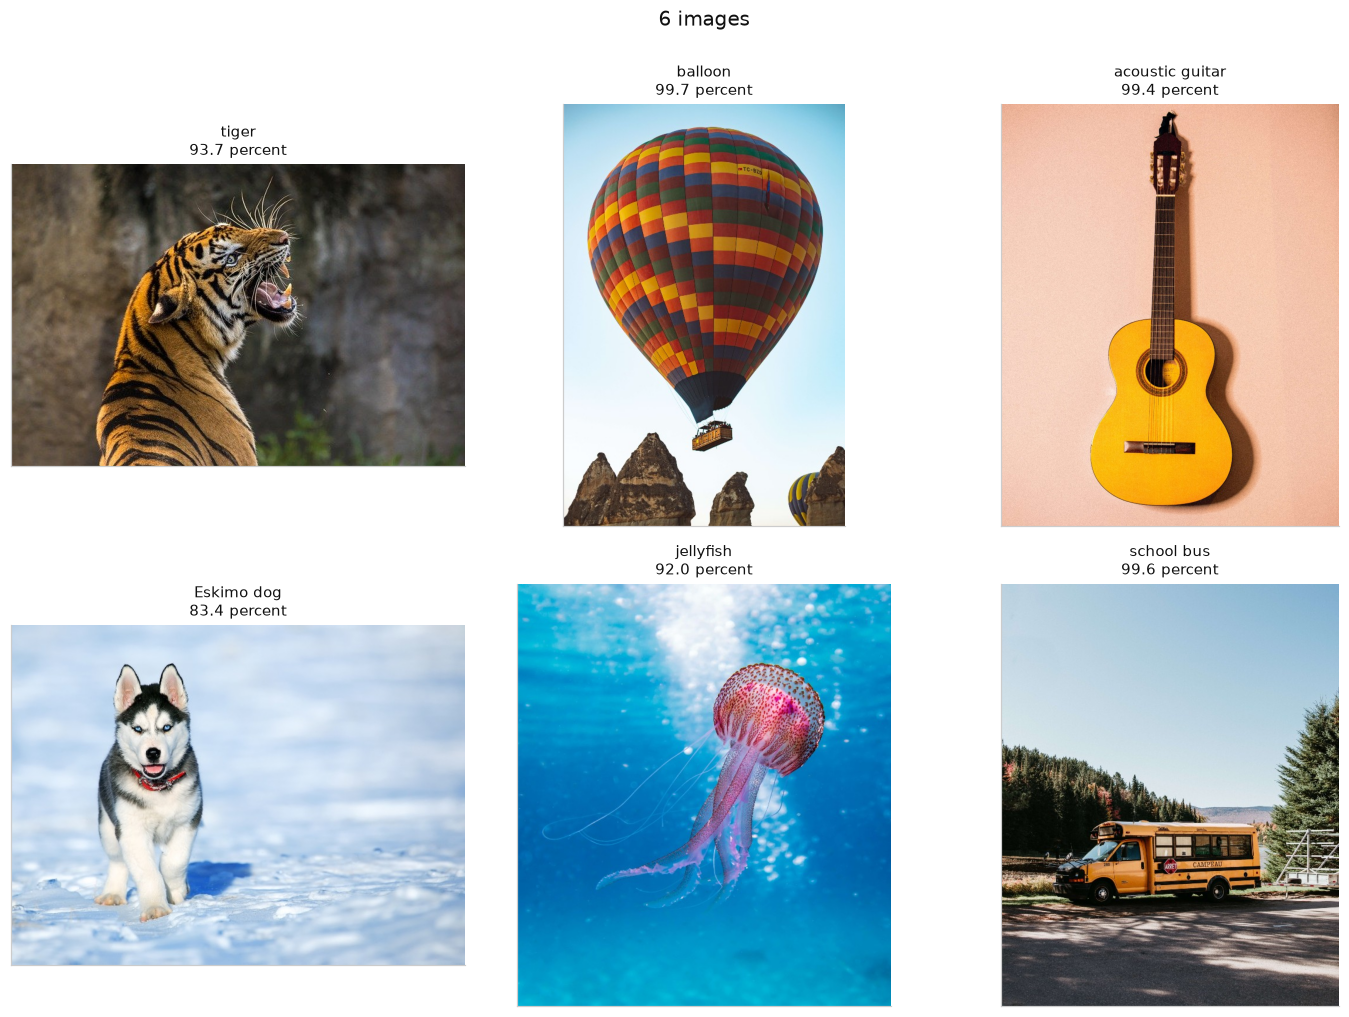

In [128]:
show_images(results, suptitle= "6 images")

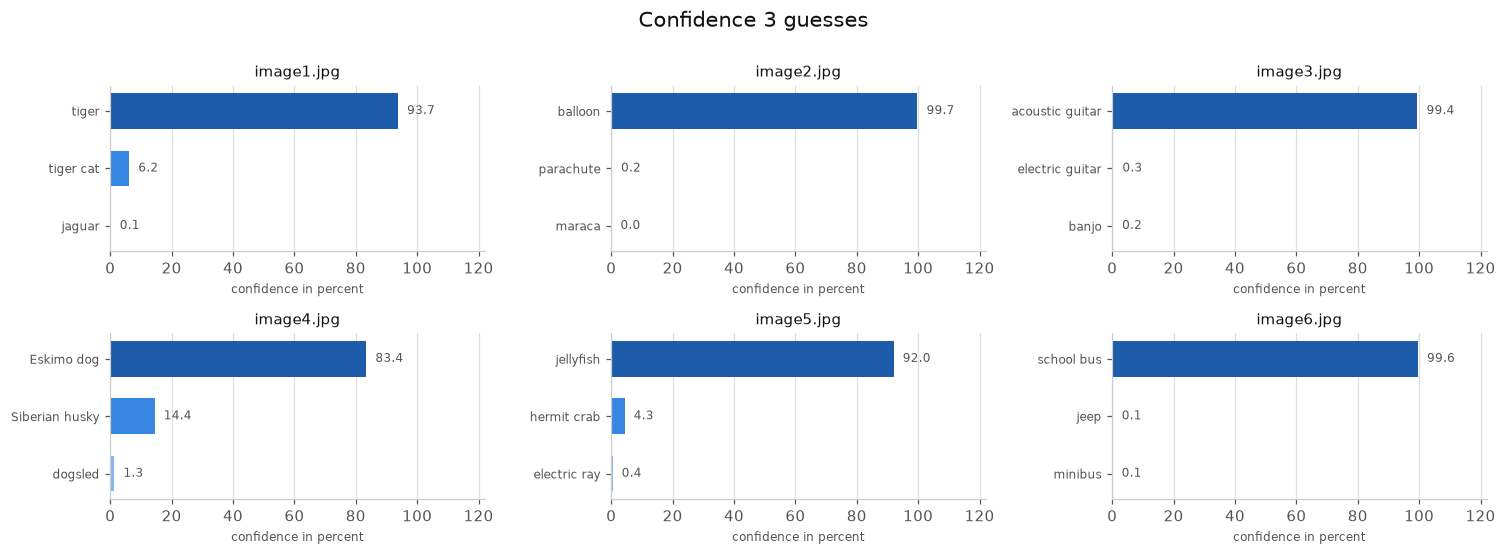

In [129]:
show_confidence(results, suptitle= "Confidence 3 guesses")


In [130]:
#3. Add more random images to the folder and see how the classification performs.
# YOUR CODE HERE

results2 = class_folder("./input/more")
print(f"{len(results2)} images classified\n")
results_table(results2)

8 images classified



,best match,confidence,second guess,second,third guess,third
image,,,,,,
Emerald_Lakes_New_Zealand.jpg,shovel,92.28,volcano,4.70,alp,0.35
Lizard.jpg,common iguana,44.14,African chameleon,33.05,green lizard,15.24
andrew.jpg,suit,73.18,Windsor tie,24.40,groom,0.44
checkerboard_color.png,web site,79.32,envelope,2.46,maze,0.83
haaland.jpg,balance beam,24.21,punching bag,20.26,racket,18.99
kitten.jpg,Egyptian cat,43.96,tiger cat,33.84,tabby,12.55
messi.jpg,torch,45.80,jersey,28.55,maillot,5.52
results1.png,shovel,20.07,alp,15.45,conch,14.97


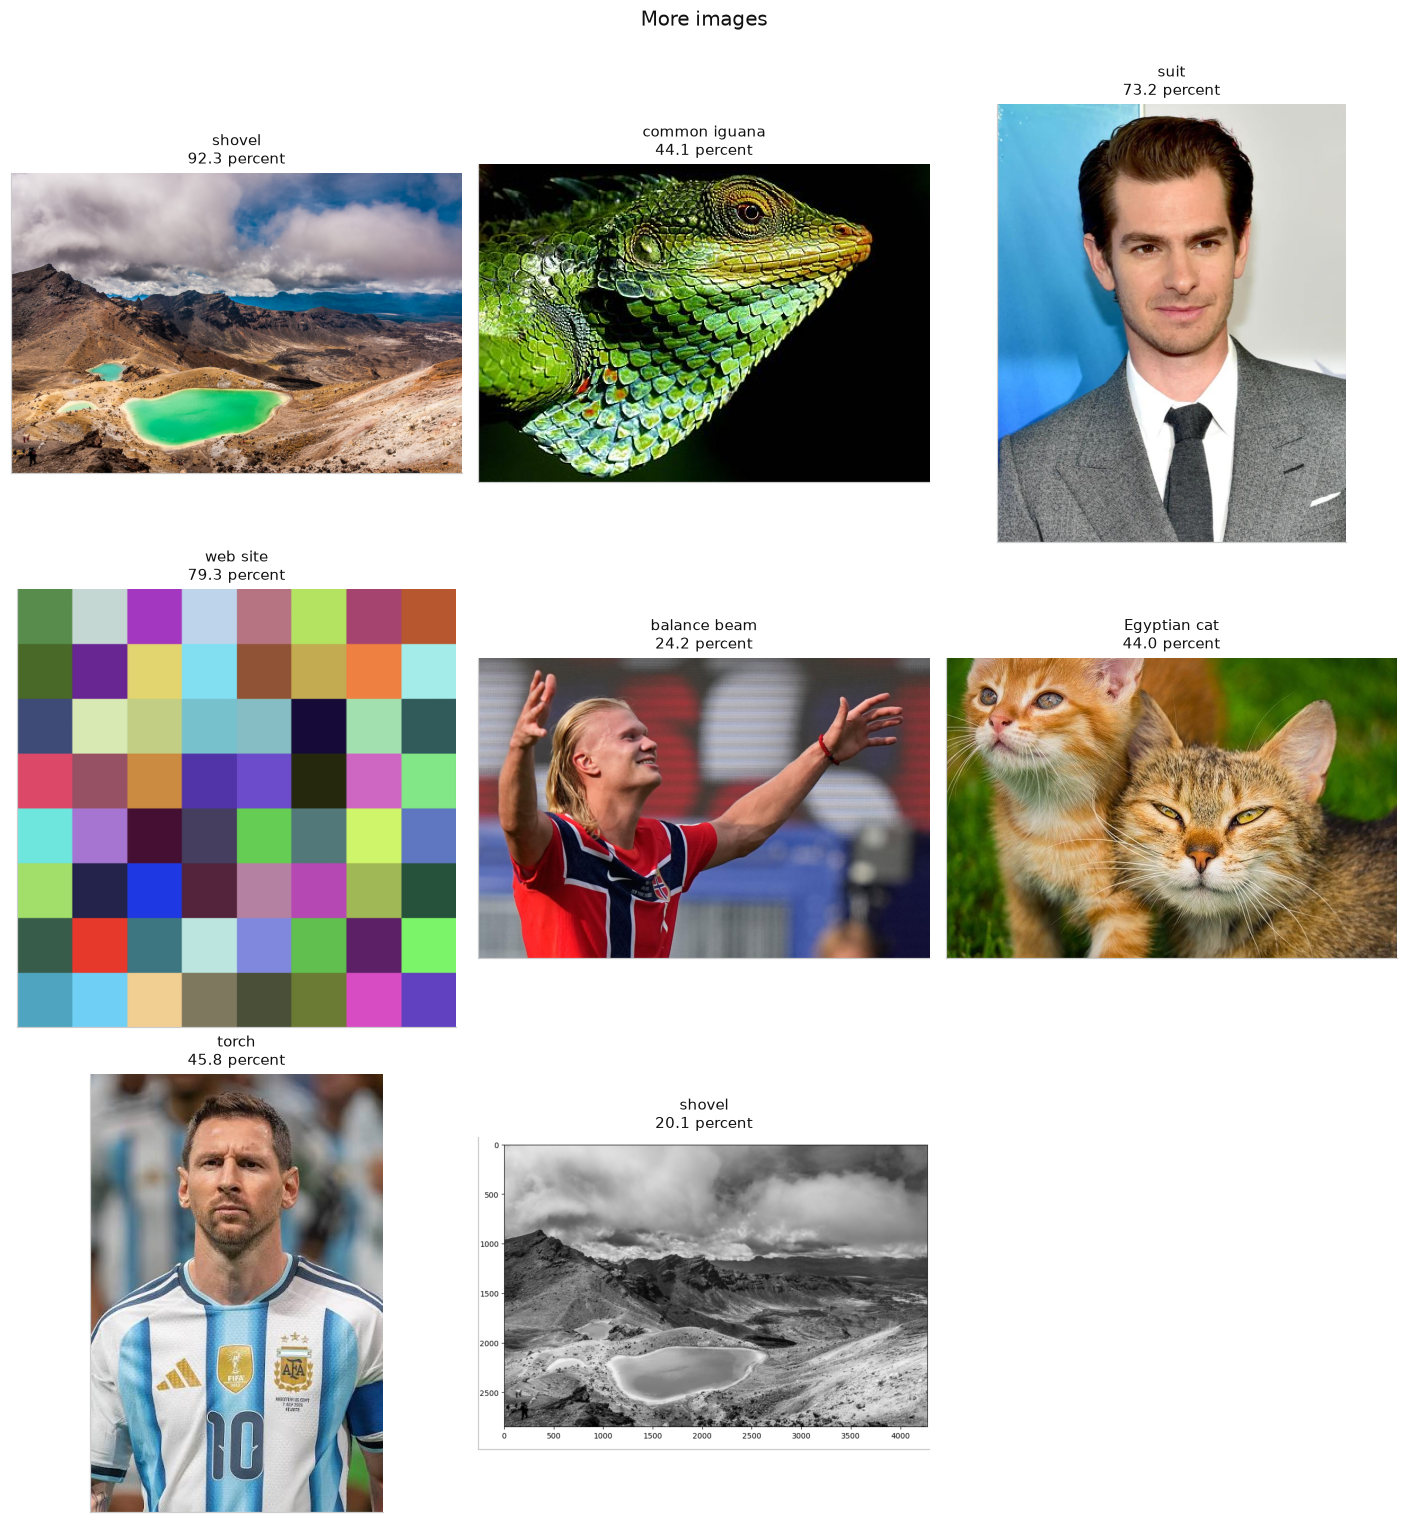

In [131]:
show_images(results2, suptitle= "More images")

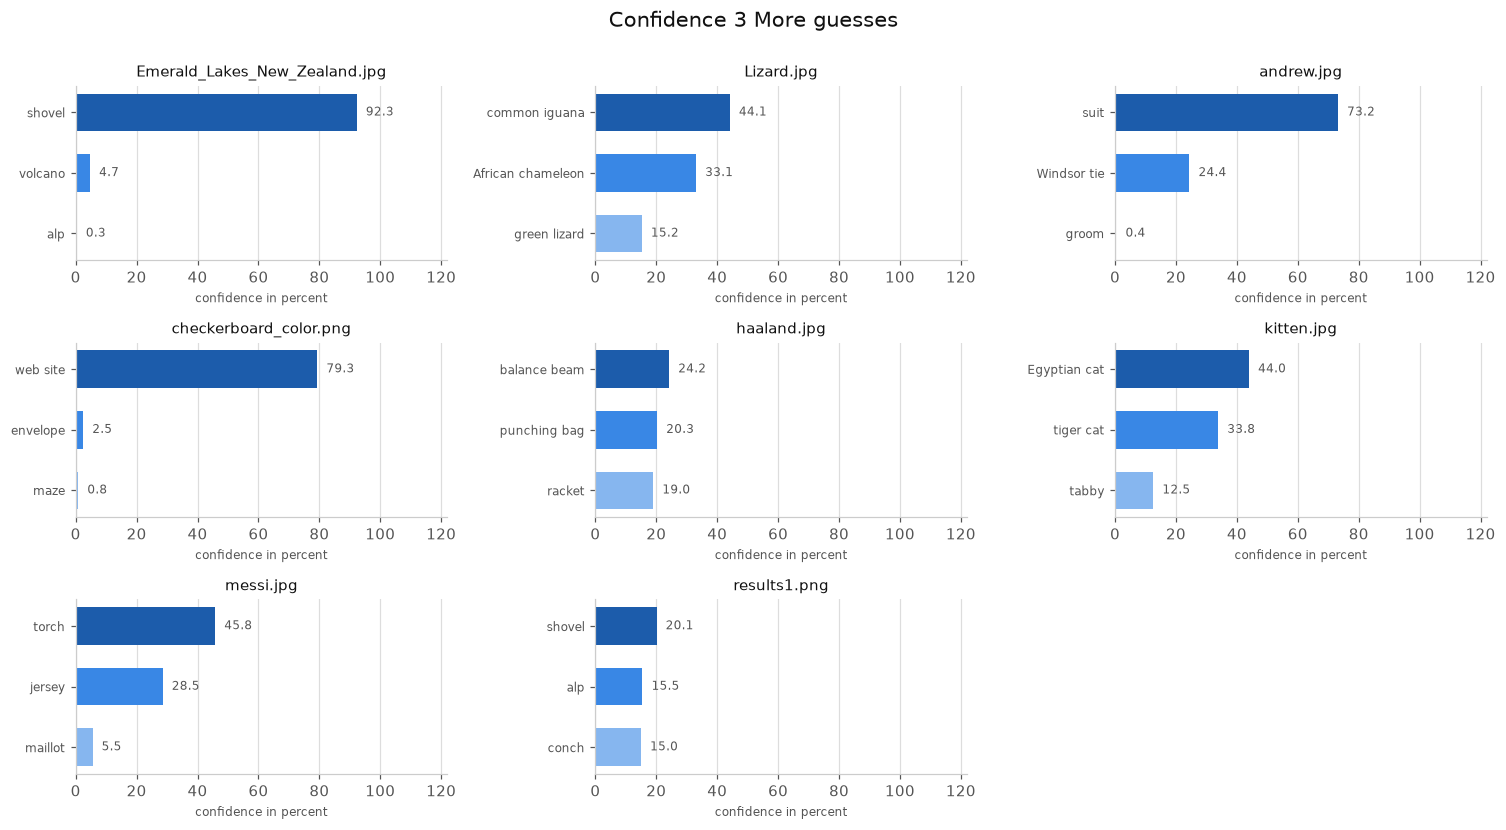

In [132]:
show_confidence(results2, suptitle= "Confidence 3 More guesses")


Reflex and answer the following:

1) What are the advantages of creating a reusable function for the object detection workflow compared to running the steps individually each time?
2) How does batch processing multiple images help you better understand the model's strengths and limitations?
3) Compare the detection results across your test images. Which types of objects were detected most accurately? Which were missed or misclassified?
4) How did image quality, lighting conditions, and object size affect the detection performance?
5) What patterns do you notice in the confidence scores across different images and object types?
6) Based on your results, what real-world applications would this object detection model be suitable for? What limitations would you need to consider?
7) If you were to improve this system for production use, what modifications would you make to the workflow or model parameters?
8) How might you extend this batch processing approach to handle video files or real-time camera input?


# Reflect and Answer

**1)** With `classify_image` and `class_folder` I could run the 6 original images and the 8 new ones with one line each. Every image gets the same blob settings (scale 0.017, mean 104, 117, 123 and size 224), so the results can be compared fairly. If I want to change something, I only have to do it in one place.

**2)** The first 6 images were all correct with 83 to 99.7 percent confidence, so the model looked almost perfect. The 8 "more" images showed something else, like a mountain lake being called a shovel at 92 percent. I only found the weak spots because I ran many different images.

**3)** Clear single objects that exist as ImageNet classes did best: tiger, balloon, guitar, jellyfish and school bus. The kitten and the lizard got the right kind of animal, but the votes were split between similar classes like Egyptian cat, tiger cat and tabby. The misses were things ImageNet has no class for. Andrew became "suit", Messi became "torch", Haaland became "balance beam" and the lake became "shovel", even though ImageNet does have a "lakeside" class.

**4)** The lake shows it best. In colour it got shovel at 92 percent. The grayscale plot of the same scene (results1.png) dropped to 20 percent, split between shovel, alp and conch. The lake photo is 4272 by 2848 pixels and gets squeezed to 224 by 224 without cropping, so both detail and shape are lost. In the close portraits the model "seems" to look at the clothes instead of the person. I did not test dark or blurry images, so I cannot say much about lighting.

**5)** When the model was right, it was usually very sure, above 83 percent. When the top guess was under 50 percent, like for the kitten, lizard, Messi and Haaland, it was either confused between similar classes or just wrong. A high score is still no guarantee. The checkerboard got "web site" at 79 percent.

**6)** It would work for sorting or tagging photos of common animals and objects, like wildlife camera images. It only knows the ImageNet classes and has no class for a person, and it always gives an answer, even for nonsense like the checkerboard. It is also classification, not detection, so the two cats in the kitten image get one label and no boxes.

**7)** I would add an "unknown" answer when confidence is low, but the shovel result shows that a threshold alone is not enough. I would crop the centre instead of squashing the image and fine tune the model on the classes I actually need, like people or football players. If the task is to find several objects in one picture, I would switch to a detector like YOLO.

**8)** `classify_image` already accepts an image array and not just a file path, so frames from `cv2.VideoCapture` can go straight in. For a live camera I would classify every few frames to keep it fast. I would also average the probabilities over the last few frames so the label does not jump between close classes like tiger cat and tabby.


## AI DECLARATION

### Ai (Claude) was used to/when
 `1`. Asked AI when i was stuck

 `2`. Grammer

 `3`. Formating nice looking Markdown parts

 `4`. Give better names to varibels where i was lazy